1D soft-Coulomb two-electron system: exact vs Kohn–Sham

PS:
**What you build.** An exactly solved two-electron system on a grid, then the same system treated with KS-DFT, so you can measure where approximate DFT fails against a true reference. Real 3D atoms never allow this beyond He.

**The system.** Two electrons on a line, nucleus of charge $Z$ at $x=0$, all Coulomb interactions softened with

$$
w(x) = \frac{1}{\sqrt{x^2+1}}
$$

$$
\hat H = -\frac12\frac{\partial^2}{\partial x_1^2} - \frac12\frac{\partial^2}{\partial x_2^2} - Z\,w(x_1) - Z\,w(x_2) + w(x_1 - x_2)
$$

- The Hamiltonian has no spin operators. Its ground state is nodeless, hence symmetric under $x_1 \leftrightarrow x_2$, hence paired with the spin singlet. You solve for one real, positive, symmetric $\Psi(x_1,x_2)$.
- Density:
$$
n(x) = 2\int |\Psi(x,x')|^2\,dx',\qquad \int n\,dx = 2
$$

**Why computation is necessary (honest framing).** Even the one-electron soft-Coulomb problem has no closed form. The two-electron problem is a 2D PDE with no analytic solution. A grid solves it easily ($N_x^2$ unknowns), which is exactly why it makes a good benchmark. For $N$ electrons the cost is $N_x^N$, which is why DFT exists. Do not claim two electrons cannot be solved; claim that a computable exact answer lets you test approximations quantitatively.

### Building blocks

**M1. One-electron solver.** Uniform grid on $[-L, L]$, 3-point finite-difference kinetic energy, `eigh_tridiagonal`. Use $h = 0.1$–$0.2$, $L \approx 10$ for atoms. Converges as $O(h^2)$. Extrapolate with

$$
E \approx E_h + \frac{E_h - E_{2h}}{3}
$$

**M2. Exact two-electron solver.**

```python
T  = sp.diags([-0.5/h**2*np.ones(N-1), 1/h**2*np.ones(N), -0.5/h**2*np.ones(N-1)], [-1, 0, 1])
I  = sp.identity(N)
X1, X2 = np.meshgrid(x, x, indexing='ij')
V  = np.tile(v, N) + np.repeat(v, N) + w(X1 - X2).ravel()
H  = sp.kron(T, I) + sp.kron(I, T) + sp.diags(V)
E, P = scipy.sparse.linalg.eigsh(H.tocsc(), k=1, which='SA', tol=1e-10)
Psi = P[:, 0].reshape(N, N) / h
n   = 2 * (Psi**2).sum(axis=1) * h
```

$N = 201$ gives 40k unknowns and runs in seconds. Fix the sign of $\Psi$ and check that the density integrates to 2. Free extension: the lowest *antisymmetric* eigenstate is the triplet, so the singlet–triplet gap costs nothing extra.

**M3. KS with exact exchange (equals restricted Hartree–Fock for two electrons).** With one doubly occupied orbital $\varphi$ and $n = 2\varphi^2$:

$$
v_x = -\frac{v_H}{2},\qquad v_\text{eff} = v_\text{ext} + \frac{v_H}{2},\qquad v_H(x) = \int n(x')\,w(x-x')\,dx'
$$

$$
E = 2\langle\varphi|\hat T|\varphi\rangle + \int n\,v_\text{ext}\,dx + E_H + E_x,
\qquad E_H = \frac12\int n\,v_H\,dx,\quad E_x = -\frac{E_H}{2}
$$

$v_H$ is a matrix–vector product with the matrix $w(x_i - x_j)$. The *exact correlation energy* then comes free, with no QMC:

$$
E_c = E_\text{exact} - E_\text{HF}
$$

**M4. LDA exchange for the 1D soft-Coulomb gas (derive it yourselves).** Uniform unpolarized gas with Fermi wavevector $k_F = \pi n/2$ and one-body density matrix

$$
\gamma_\sigma(x) = \frac{k_F}{\pi}\,\frac{\sin(k_F x)}{k_F x}
$$

Inserting into $E_x = -\tfrac12\sum_\sigma\iint w(x-x')\,|\gamma_\sigma(x,x')|^2$ gives the exchange energy density

$$
n\,e_x(n) = -\frac{n^2}{2}\,J(k_F),
\qquad
J(k) = \int_0^\infty \frac{\sin^2 t}{t^2\sqrt{t^2+k^2}}\,dt
$$

Tabulate on a log-spaced $n$ grid, build a `CubicSpline` in $\ln n$, and take

$$
v_x(n) = \frac{d\,[n\,e_x(n)]}{dn}
$$

from the spline derivative. Check: $e_x \to -\tfrac12$ as $n \to \infty$.

**M5. LDA correlation.** The parametrization for exactly this interaction is in Helbig, Fuks, Casula, Verstraete, Marques, Tokatly, Rubio, Phys. Rev. A 83, 032503 (2011), arXiv:1101.2564 (QMC-based fit, $a=1$, unpolarized and polarized). Transcribe the coefficients from Table I of the paper. In 1D,

$$
r_s = \frac{1}{2n}
$$

Validate by reproducing the 1D He energy they report. Fallback if this stalls: drop LDA-C; the project still works with LDA-X against exact, since the exact $E_c$ comes from M3.

**M6. Exact xc potential (no iteration needed for $N=2$).** For a singlet pair, $\varphi = \sqrt{n/2}$ exactly, so the KS equation can be solved for the potential directly:

$$
v_s(x) = \varepsilon + \frac{\varphi''(x)}{2\,\varphi(x)},
\qquad
v_{xc} = v_s - v_\text{ext} - v_H,
\qquad
v_c = v_{xc} + \frac{v_H}{2}
$$

- Fix the constant $\varepsilon$ so $v_{xc} \to 0$ at large $|x|$. In exact DFT, $\varepsilon = -I$.
- Restrict to the region $n \gtrsim 10^{-8}$, because $\varphi''/\varphi$ amplifies noise in the tails.
- Plot exact $v_{xc}$ against the LDA $v_x$. The LDA potential decays exponentially; the exact one decays as $-1/|x|$.
- Optional method comparison: Zhao–Morrison–Parr iteration $v_s \leftarrow v_s + \alpha\,(n_\text{KS} - n_\text{exact})$ (slow and noisy), or Wu–Yang. Use it only to cross-check the direct formula.

### Reference numbers (from my own calculation, $h = 0.1$ with Richardson extrapolation; reproduce before trusting)

| Quantity | Value (Ha) |
|---|---|
| 1D H atom ($Z=1$, one electron) | $-0.6698$ |
| 1D He$^+$ ($Z=2$, one electron) | $-1.4834$ |
| 1D He, exact | $-2.2383$ |
| 1D He, RHF (= KS-EXX) | $-2.2242$ |
| Exact correlation energy $E_c$ | $-0.0140$ |
| Exact ionization energy $I$ | $0.7548$ |

Exact ionization energy $I$ | $0.7548$ |
| 1D He, LDA exchange-only | $-2.158$ |
| $E_x$: LDA vs exact ($-E_H/2$) | $-0.654$ vs $-0.724$ |

LDA-X underestimates exchange by about 10%, while correlation is only about 0.014 Ha. So in 1D He most of the LDA error is exchange. I recall the H and He values matching Helbig et al. and Wagner et al. (about $-0.670$ and $-2.238$), but check the paper tables.

### Extension: stretched H$_2$ (strongest extension)

Two soft nuclei at $\pm R/2$ ($Z=1$ each) with nuclear repulsion $w(R)$ added. Grow the box with $R$ ($L = R/2 + 9$ worked). My results ($h = 0.15$, accuracy a few $10^{-4}$ Ha):

| $R$ | Exact | RHF (= KS-EXX) | LDA-X only |
|---|---|---|---|
| 1 | $-1.4134$ | $-1.3947$ | $-1.3331$ |
| 2 | $-1.4421$ | $-1.4060$ | $-1.3561$ |
| 4 | $-1.3509$ | $-1.1904$ | $-1.1281$ |
| 6 | $-1.3395$ | $-1.0693$ | $-1.0729$ |
| 10 | $-1.3398$ | $-1.0224$ | $-1.0651$ |

- The exact curve has a minimum near $R \approx 2$ and dissociates to $2\times(-0.6698) = -1.3396$ Ha.
- RHF dissociates about 0.32 Ha too high. The exact $|E_c|$ grows from 0.015 at $R=0.5$ to 0.317 at $R=10$. This is static correlation: the restricted wavefunction forces 50% ionic character at any $R$.
- LDA-X also fails by about 0.27 Ha at $R=10$. I have not run full LDA-XC; expect the same failure, and treat it as a test of the claim that a better xc functional does not fix static correlation error.
- Plot exact $v_{xc}(x)$ at $R = 1, 4, 8$. At large $R$ a peak/step develops at the bond midpoint, which no LDA reproduces. This is the highlight figure.

### Parameter studies (pick two or three)

1. Grid convergence in $h$ and $L$ (mandatory; it gives your error bar).
2. SCF mixing $\alpha$ versus iteration count, including divergence near $\alpha = 1$.
3. $Z$-scan for two-electron ions: H$^-$, He, Li$^+$, Be$^{2+}$. Plot LDA-X relative error and $|E_c|$ against $Z$ (high-density limit).
4. Softening parameter $a$ in $w(x) = 1/\sqrt{x^2+a^2}$, beyond $a=1$.
5. HOMO test: exact $-\varepsilon_\text{HOMO} = I = 0.7548$ Ha. LDA should give a smaller value because of the wrong asymptotic decay.

### Pitfalls

- Wrong sign or scale on $v_x$: check $E_x^\text{LDA}$ against $-E_H/2$.
- Energy double counting: use $E = T_s + \int n\,v_\text{ext} + E_H + E_{xc}$, not a sum of eigenvalues alone.
- Box too small at large $R$: if the energy drifts as $L$ grows, enlarge it.
- Memory: $N_x^2$ grows fast; $R = 10$ is about 70k unknowns, still fine.
- Scope: finish M1–M3 first. That alone is a complete, defensible project before touching M4–M6.

### Resources

- Capelle, arXiv:cond-mat/0211443.
- Helbig et al., PRA 83, 032503 (2011), arXiv:1101.2564 (LDA parametrization, 1D He benchmark).
- Wagner, Stoudenmire, Burke, White, Phys. Chem. Chem. Phys. 14, 8581 (2012), "Reference electronic structure calculations in one dimension". Check which interaction they use before copying numbers; it may differ from $1/\sqrt{x^2+1}$.
- Cohen, Mori-Sánchez, Yang, Science 321, 792 (2008): delocalization and static correlation error.
- Burke, J. Chem. Phys. 136, 150901 (2012).
- Wu and Yang, J. Chem. Phys. 118, 2498 (2003): potential inversion.

---

In [28]:
!pip install numpy scipy matplotlib

Let us first make the exact wave equation solver in 1d to setup the bechmark here : this for the case of H-

[-919.83379722]


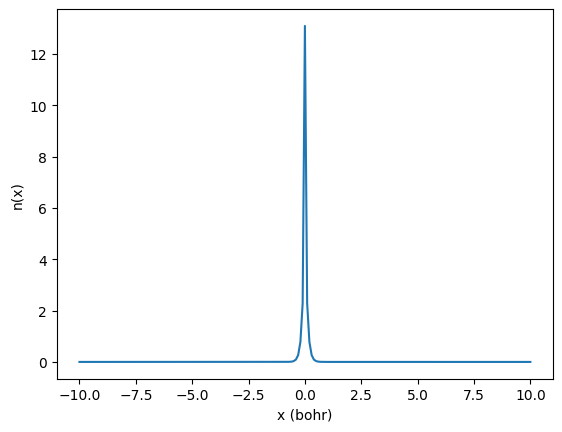

In [42]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla          # <-- added
import matplotlib.pyplot as plt

a=0.001
L=10.0
h=0.1
N = 201
x = np.linspace(-L, L, N, endpoint =  True  )    # odd N, x = 0 on the grid


def w(x, a):
    return 1.0 / np.sqrt(x**2 + a**2)

def v_1atom(x, Z, a):# just realized it is better to keep z seperate as compared to within the w function
    return -Z * w(x, a)

def kinetic_matrix(N, h):
    return sp.diags([-0.5 / h**2 * np.ones(N - 1),
                     1.0 / h**2 * np.ones(N),
                     -0.5 / h**2 * np.ones(N - 1)], [-1, 0, 1], format="csc")# csc is good for storage as we dont have to store the entire matrix
                     # I have used finite difference operator here

def H_two_electron(x, h, v, a):
    N = len(x)
    T = kinetic_matrix(N, h)# basically our kinetic energy operator on the combined sci vector
    I = sp.identity(N, format="csc")
    X1, X2 = np.meshgrid(x, x, indexing="ij")# meshgrid is an oddly weird function
    V = np.repeat(v, N) + np.tile(v, N) + w(X1 - X2, a).ravel()# basically converting the 2D grid of all possible coordinates into a single vector, very concisely written indeed
    return (sp.kron(T, I) + sp.kron(I, T) + sp.diags(V)).tocsc()

E,P = spla.eigsh(H_two_electron(x, 0.1,v_1atom(x,1,a), a),k=1,which = 'SA',tol = 1e-10)   # <-- sp -> spla
# so the explanation here i htink is in that after solving the system stays in the lowest eigen value pair , basically meaning the system settles into the lowest energy state
# now we have solved it for the H- case let us plot it and see how it looks
Psi = P[:, 0].reshape(N, N) / h        # flat vector -> N x N table, Psi[i, j] = Psi(x_i, x_j)
if Psi.sum() < 0:                      # eigenvector sign is arbitrary
    Psi = -Psi
n = 2 * (Psi**2).sum(axis=1) * h       # n(x_i) = 2 * sum_j |Psi_ij|^2 * h
plt.plot(x, n); plt.xlabel("x (bohr)"); plt.ylabel("n(x)")
print(E);


**Side note : observe that as a  reduces (the softening factor) this graph spikes more and more , this spike is basically called a cusp and is predicted rightly by Kato's theorem which states that the first derivative of the wave function if discontinuous when 2 particles meet ......**

lets do the same for H2 now (drastically increasing molecular diameter )

Text(0, 0.5, 'n(x)')

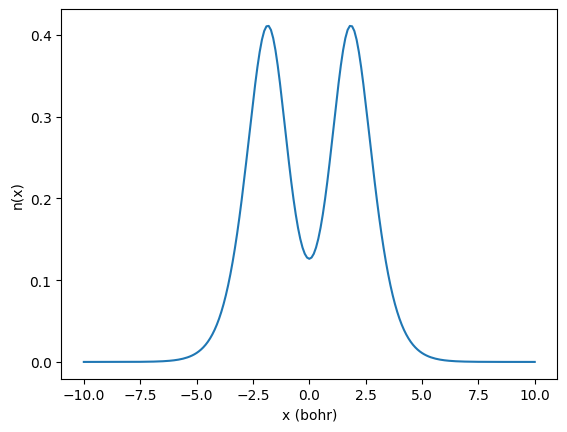

In [43]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla          # <-- added
import matplotlib.pyplot as plt


L=10.0
h=0.1
N = 201
x = np.linspace(-L, L, N, endpoint =  True  )    # odd N, x = 0 on the grid


def w(x, a=1.0):
    return 1.0 / np.sqrt(x**2 + a**2)


def v_1atom(x, Z, a=1.0):# just realized it is better to keep z seperate as compared to within the w function
    return -Z * w(x, a)
def v_2atom(x,z,a=1.0,R = 3.5):
    return -z*w(x+R/2,a)- z*w(x-R/2,a)
def kinetic_matrix(N, h):
    return sp.diags([-0.5 / h**2 * np.ones(N - 1),
                     1.0 / h**2 * np.ones(N),
                     -0.5 / h**2 * np.ones(N - 1)], [-1, 0, 1], format="csc")# csc is good for storage as we dont have to store the entire matrix
                     # I have used finite difference operator here

def H_two_electron(x, h, v, a=1.0):
    N = len(x)
    T = kinetic_matrix(N, h)# basicaaly our kinetic energy operator on the compined sci vector
    I = sp.identity(N, format="csc")
    X1, X2 = np.meshgrid(x, x, indexing="ij")# meshgrid is an oddly weird function
    V = np.repeat(v, N) + np.tile(v, N) + w(X1 - X2, a).ravel()# basically converting the @d grid of all possible coordinates into a single vector, very concisely written indeed
    return (sp.kron(T, I) + sp.kron(I, T) + sp.diags(V)).tocsc()

E,P = spla.eigsh(H_two_electron(x, 0.1,v_2atom(x,1), 0.2),k=1,which = 'SA',tol = 1e-10)   # <-- sp -> spla
# so the explanation here i htink is in that after solving the system stays in the lowest eigen value pair , basically meaning the system settles into the lowest energy state
# now we have solved it for the H- case let us plot it and see how it looks
Psi = P[:, 0].reshape(N, N) / h        # flat vector -> N x N table, Psi[i, j] = Psi(x_i, x_j)
if Psi.sum() < 0:                      # eigenvector sign is arbitrary
    Psi = -Psi
n = 2 * (Psi**2).sum(axis=1) * h       # n(x_i) = 2 * sum_j |Psi_ij|^2 * h
plt.plot(x, n); plt.xlabel("x (bohr)"); plt.ylabel("n(x)")









Approximations used: finite difference method analysis for the second derivative , also the fact using the fact that we are computing at discrete points

Side idea, to reduce compute , run metropolis hashtings algorithm , although it would recue compute, IT will affect the error , goes against  the  idea of exact sol for comparison .

## M3

Let us run the same system through the Kohn-Sham approach to things. How this works is that the Hohenberg-Kohn theorems laid the theoretical foundation for us to pursue finding a way of finding the *ground state* electron density straightaway without solving for the *ground state* wavefunction. We use the newly proven theorem that the total energy is a functional of the density ρ.

The issue is that the exact kinetic energy functional is not known.

From this arises the crux of the matter: I want to bypass the need to solve for the kinetic energy functional. I use the Kohn-Sham equations to this end: $$\left(-{\frac {\hbar ^{2}}{2m}}\nabla ^{2}+v_{\text{eff}}(\mathbf {r} )\right)\varphi _{i}(\mathbf {r} )=\varepsilon _{i}\varphi _{i}(\mathbf {r} )$$

The electron density is then recovered by summing over the occupied orbitals: $\rho(\mathbf{r}) = \sum_i \vert{}\psi_i(\mathbf{r})\vert{}^2$. **This deals with fictitious non-interaction electrons to solve for orbitals** and hence is a simple summation of orbital probabilities. $φ_i(\mathbf{r})$ is the *Kohn-Sham Orbital* for fictitious non-interacting electron $i$.

The effective potential $V_{KS}(\mathbf{r})$ in the Kohn-Sham equations is split into three parts:$$V_{KS}(\mathbf{r}) = V_{ext}(\mathbf{r}) + V_H(\mathbf{r}) + V_{xc}(\mathbf{r})$$

We then loop through possible values of ρ and then if after iterating through we converge on a value, we can deal with the Energy then.

Mention : there is another wave function approximation that is standard based completely on the monte carlo methods(to be specific "Monte Carlo trial function") i shall try it in some time , also would like to simulate Hartree Fock approximation for the wave function and also using slaters determinants ,..methods as well

Self-consistent field (SCF) loop
1. Guess n(0) e.g. the bare-nucleus orbital, n = 2φ^2.
2. Build vH, vxc, and veff ; solve the 1D eigenproblem for the lowest orbital.
3. New density n_out = 2φ^2.
4. Mix: n_in ← α n_out + (1 − α) n_in.
5. Stop when ∥nout − nin∥ (or ∆E) falls below tolerance.
Plain iteration (α = 1) tends to oscillate or diverge because the response of veff to n overshoots;
small α converges slowly. Plotting iterations-to-convergence against α is parameter study 2.

Setting up the approach to applying the Kohn-Sham method to guess the density. In this case, for 2 electrons, this is equal to the restricted Hartree-Fock method.

In [31]:
h_KS = 0.1
a_KS = 1 # softening of Coloumb
N_KS = 201
x_KS = np.linspace(-L, L, N_KS, endpoint=True)
Z = 1 # Identical nuclei for now

# First one nucleus

def w_KS(x, a=a_KS): # the 1/|x| term equivalent in the soft-Coulomb case.
    return 1.0 / np.sqrt(x**2 + a**2)
def v_ext(Z, x, a=a_KS):
  return -Z*w_KS(x,a)
def T_1e(N, h): # Tridiagonal matrix of KE
  return sp.diags([-0.5/h**2*np.ones(N-1),
                   1.0/h**2*np.ones(N),
                   -0.5/h**2*np.ones(N-1)],
                    [-1, 0, 1], format="csc")
def W_grid(N, h, x, a=a_KS): # creates a matrix of all i-j pair distances' w(x)
  W = 1.0/np.sqrt((x[:,None] - x[None,:])**2 + a**2)
  # W is an N x N matrix
  return W


The initial guess.


Text(0, 0.5, 'n(x)')

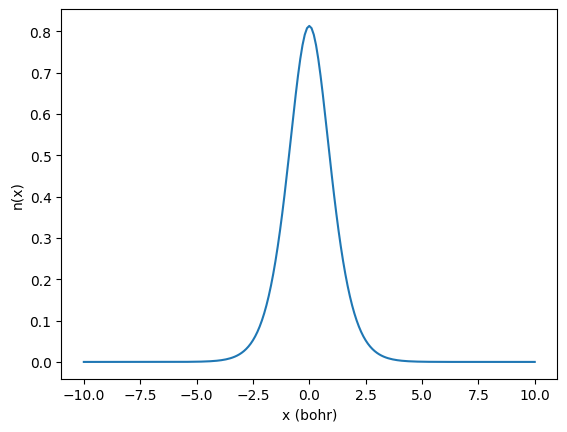

In [32]:
import scipy as s

alpha = 0.4 # The alpha needed for a convex combination of the guesses of density

# for the first guess i'll just ignore the need for v_xc and v_h.
# T+diag(v_ext) is the Kohn-Sham Hamiltonian
T = T_1e(N_KS, h_KS)
V = v_ext(Z, x_KS)

# select i selects from indices, and select_range chooses which indices. 0,0 is the lowest of each.
# returns as 1D and 2D arrays
min_eps, min_phi = s.linalg.eigh_tridiagonal(T.diagonal()+V, T.diagonal(k=1), select="i", select_range=(0,0))
min_phi = min_phi[:,0]/np.sqrt(h_KS)
# density is n
n = 2*min_phi*np.conj(min_phi)

plt.plot(x_KS, n)
plt.xlabel("x (bohr)")
plt.ylabel("n(x)")

The self-consistent loop to guess the 𝜌.
I now need to estimate both $V_H$ and $V_{xc}$ using the first guess for 𝜌.

In [33]:
err_thres = 1e-6 # |n_init - n_new| < err_thres
def V_H(n, h, x, a=a_KS): # Hartree Potential
  W = W_grid(n, h, x, a) # W matrix formed, now to dot it with n
  return h*(W @ n)

Here, the issue with this is that it uses the density from both electrons to calculate $v_H$, which means the contribution from the electron on itself is also counted.

Since both electrons have the same orbital (symmetry), we can halve $v_H$ in this particular case to deal with it.

This, however, is not so easy to generalise. This is what v_XC does normally.

So, in this case, $v_{X}$ is simply $- v_H/2$. $v_C = 0$.

In [34]:
alpha = 0.4 # conservative convex combination
eps = 0 # eigenvalue of kohn sham, NOT actual energy

while True: # Like a do while loop
  v_H = V_H(n,h_KS,x)
  v_XC = -0.5*v_H

  # Now utilising the v_H and v_XC
  min_new_eps, new_phi = s.linalg.eigh_tridiagonal(T.diagonal()+V+v_H+v_XC, T.diagonal(k=1), select="i", select_range=(0,0))
  new_phi = new_phi[:,0]/np.sqrt(h_KS)

  # density is n
  n_new = 2*new_phi*np.conj(new_phi)

  if np.linalg.norm(n_new - n) < err_thres:
    n = n_new
    eps = min_new_eps[0]
    break
  else:
    n = alpha*n_new + (1-alpha)*n

Text(0, 0.5, 'n(x)')

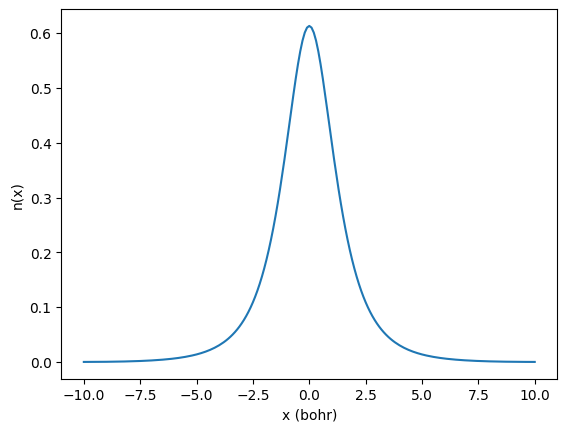

In [35]:
plt.plot(x_KS, n)
plt.xlabel("x (bohr)")
plt.ylabel("n(x)")

Now, I need to calculate the ground state energy from density. In this case, again, it's neat that I can simply use 2*eps + E_x = E_KS.

Note that T_s is not the true kinetic energy, it's simply the kinetic energy of the fictitious non interacting electrons. The disparity between T_s and true T is accounted for in the E_x term.

In [36]:
# Energy from converged n
v_H = V_H(n, h_KS, x) # Hartree potential
E_H = 0.5 * h_KS * (n@v_H) # Hartree energy, avoiding double counting
E_x = -0.5*E_H # same reasoning as for v_x earlier
E_c = 0.0
T_s = 2*h_KS* (np.conj(new_phi) @ (T @ new_phi)) # "kinetic energy" of non interacting electrons
E_ext = h_KS * (n@V) # due to nuclear attraction

E_KS = T_s + E_ext + E_H + E_x

print("integral of n        :", h_KS * np.sum(n))      # must be 2
print("E_KS (term by term)  :", E_KS)
# To see if any unexpected behaviour is there.
print("E_KS (2*eps - E_H/2) :", 2*eps + E_x)

integral of n        : 1.9999999999999998
E_KS (term by term)  : -0.6918227779155561
E_KS (2*eps - E_H/2) : -0.691822826796449


Now the same Kohn-Sham (= restricted Hartree-Fock) process for an H2 molecule. Two nuclei of charge 1 at x = ±R/2.
What changes: v_ext now has two wells, and the total energy gets an extra nucleus-nucleus repulsion w(R).
For 2 electrons in one orbital, v_x = -v_H/2 still holds exactly.

In [37]:
R_H2 = 3.5 # internuclear distance, same as the exact solver (nuclei at +-R/2)
L_H2 = 10.0 # use 12.5 if R_H2 = 7, the box must grow with R
h_H2 = 0.1
N_H2 = int(round(2*L_H2/h_H2)) + 1
x_H2 = np.linspace(-L_H2, L_H2, N_H2, endpoint=True)

def v_ext_H2(x, R, a=a_KS): # two nuclei of charge 1 at -R/2 and +R/2
  return -w_KS(x - R/2, a) - w_KS(x + R/2, a)

Initial guess

In [38]:
# for the first guess i'll again ignore v_H and v_xc.
T_H2 = T_1e(N_H2, h_H2)
V_H2 = v_ext_H2(x_H2, R_H2)

eps_H2, phi_H2 = s.linalg.eigh_tridiagonal(T_H2.diagonal()+V_H2, T_H2.diagonal(k=1), select="i", select_range=(0,0))
phi_H2 = phi_H2[:,0]/np.sqrt(h_H2)
# density is n
n_H2 = 2*phi_H2*np.conj(phi_H2)

Self Consistent KS Loop

In [39]:
alpha = 0.4 # conservative convex combination
eps_H2 = 0 # eigenvalue of kohn sham, NOT actual energy

while True: # Like a do while loop
  v_H_H2 = V_H(n_H2, h_H2, x_H2)
  v_XC_H2 = -0.5*v_H_H2

  # Now utilising the v_H and v_XC
  min_new_eps_H2, new_phi_H2 = s.linalg.eigh_tridiagonal(T_H2.diagonal()+V_H2+v_H_H2+v_XC_H2, T_H2.diagonal(k=1), select="i", select_range=(0,0))
  new_phi_H2 = new_phi_H2[:,0]/np.sqrt(h_H2)

  # density is n
  n_new_H2 = 2*new_phi_H2*np.conj(new_phi_H2)
  # the molecule is mirror symmetric, so the true density is too. Forcing it stops the
  # charge from "sloshing" between the two nuclei every iteration at large R.
  n_new_H2 = 0.5*(n_new_H2 + n_new_H2[::-1])

  if np.linalg.norm(n_new_H2 - n_H2) < err_thres:
    n_H2 = n_new_H2
    eps_H2 = min_new_eps_H2[0]
    break
  else:
    n_H2 = alpha*n_new_H2 + (1-alpha)*n_H2

Plotting

Text(0, 0.5, 'n(x)')

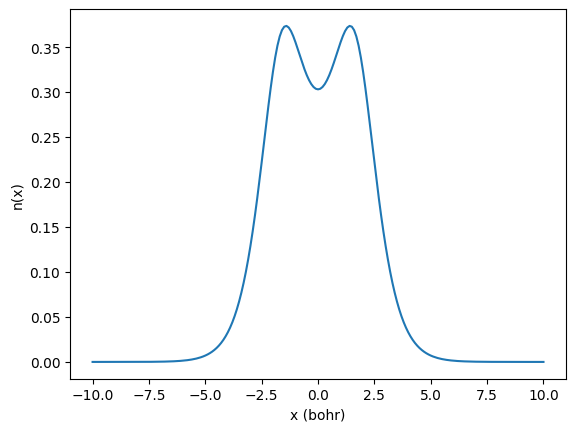

In [44]:
plt.plot(x_H2, n_H2)
plt.xlabel("x (bohr)")
plt.ylabel("n(x)")

Energy Calculations

In [41]:
# Energy from converged n
v_H_H2 = V_H(n_H2, h_H2, x_H2) # Hartree potential
E_H_H2 = 0.5 * h_H2 * (n_H2@v_H_H2) # Hartree energy, avoiding double counting
E_x_H2 = -0.5*E_H_H2 # same reasoning as for v_x earlier
E_c_H2 = 0.0
T_s_H2 = 2*h_H2* (np.conj(new_phi_H2) @ (T_H2 @ new_phi_H2)) # "kinetic energy" of non interacting electrons
E_ext_H2 = h_H2 * (n_H2@V_H2) # due to attraction to both nuclei

# E_nn_H2 = w_KS(R_H2) # NEW: repulsion between the two nuclei

E_KS_H2 = T_s_H2 + E_ext_H2 + E_H_H2 + E_x_H2 #+ E_nn_H2

print("integral of n        :", h_H2 * np.sum(n_H2))      # must be 2
print("E_KS (term by term)  :", E_KS_H2)
# To see if any unexpected behaviour is there.
print("E_KS (2*eps + E_x + E_nn) :", 2*eps_H2 + E_x_H2) #+ E_nn_H2)

integral of n        : 1.9999999999999993
E_KS (term by term)  : -1.2642332211393001
E_KS (2*eps + E_x + E_nn) : -1.264233209883883


##M4
What's new in M4? I now use the local density approximation (LDA) to simulate the electron density as a "Fermi gas"